# Proyek Akhir Pembelajaran Mesin (INF62325)
## Tahap 3 — Varian 2 (Parameter & Perlakuan Data): Klasifikasi k-NN vs Naive Bayes (`03_varian_2.ipynb`)

* **Mata Kuliah**: Pembelajaran Mesin (INF62325) — Program Studi S1 Informatika, UIN Siber Syekh Nurjati Cirebon
* **Dosen Pengampu**: Ardi Susanto, S.Kom., M.Cs.
* **Kelas**: Informatika 5C
* **Paket Dataset**: *Default of Credit Card Clients* (UCI Machine Learning Repository, ID: 350)
* **Anggota Penanggung Jawab Varian 2 (Parameter & Perlakuan Data)**: **Kamalul Iman (`2488010054`)**
* **Tujuan Varian 2**:
  Menguji pengaruh variasi **hyperparameter** dan **perlakuan data** terhadap performa klasifikasi **k-NN** dan **Gaussian Naive Bayes** pada dataset hasil `02_praproses.ipynb` (`data_praproses_dasar.csv`, target **`Y`**), meliputi:
  1. Perbandingan metode penskalaan data (`StandardScaler` vs `MinMaxScaler` vs `RobustScaler` yang tahan terhadap *outlier* finansial).
  2. Penyetelan parameter **k-NN**: iterasi lengkap seluruh nilai tetangga ganjil **$k \in \{3, 5, 7, 9, 11, 13, 15, 17, 19, 21\}$** (mencakup rentang $3 \text{ s.d. } 19$ pada proposal), metrik jarak (`euclidean` vs `manhattan`), dan skema pembobotan (`uniform` vs `distance`).
  3. Penyetelan parameter **Gaussian Naive Bayes**: variasi `var_smoothing` untuk menstabilkan estimasi varians fitur.
  4. Perlakuan **penyeimbangan kelas (*Class Imbalance Handling*)** pada data latih saja (*Random Oversampling*) serta analisis **ambang batas probabilitas (*Threshold Tuning*)** untuk memaksimalkan *F1-Score* dan *Recall* deteksi gagal bayar.

### Langkah 1 — Impor Pustaka & Pemuatan Dataset Hasil Praproses (`Target = Y`)

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.utils import resample
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
print("Pustaka eksperimen Varian 2 berhasil dimuat.")

Pustaka eksperimen Varian 2 berhasil dimuat.


In [2]:
UCI_FEATURE_MAP = {
    'X1': 'LIMIT_BAL', 'X2': 'SEX', 'X3': 'EDUCATION', 'X4': 'MARRIAGE', 'X5': 'AGE',
    'X6': 'PAY_0', 'X7': 'PAY_2', 'X8': 'PAY_3', 'X9': 'PAY_4', 'X10': 'PAY_5', 'X11': 'PAY_6',
    'X12': 'BILL_AMT1', 'X13': 'BILL_AMT2', 'X14': 'BILL_AMT3',
    'X15': 'BILL_AMT4', 'X16': 'BILL_AMT5', 'X17': 'BILL_AMT6',
    'X18': 'PAY_AMT1', 'X19': 'PAY_AMT2', 'X20': 'PAY_AMT3',
    'X21': 'PAY_AMT4', 'X22': 'PAY_AMT5', 'X23': 'PAY_AMT6',
    'x1': 'LIMIT_BAL', 'x2': 'SEX', 'x3': 'EDUCATION', 'x4': 'MARRIAGE', 'x5': 'AGE',
    'x6': 'PAY_0', 'x7': 'PAY_2', 'x8': 'PAY_3', 'x9': 'PAY_4', 'x10': 'PAY_5', 'x11': 'PAY_6',
    'x12': 'BILL_AMT1', 'x13': 'BILL_AMT2', 'x14': 'BILL_AMT3',
    'x15': 'BILL_AMT4', 'x16': 'BILL_AMT5', 'x17': 'BILL_AMT6',
    'x18': 'PAY_AMT1', 'x19': 'PAY_AMT2', 'x20': 'PAY_AMT3',
    'x21': 'PAY_AMT4', 'x22': 'PAY_AMT5', 'x23': 'PAY_AMT6'
}

def load_credit_card_dataset():
    try:
        from ucimlrepo import fetch_ucirepo
        dataset = fetch_ucirepo(id=350)
        df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)
        print("Memuat dataset dari ucimlrepo (ID=350) — selaras 01_Eksplorasi.ipynb")
        return df
    except Exception:
        pass

    local_candidates = [
        'default of credit card clients.xls',
        'default_of_credit_card_clients.xls',
        'default_of_credit_card_clients.csv',
        'UCI_Credit_Card.csv'
    ]
    for fname in local_candidates:
        if os.path.exists(fname):
            print(f"Memuat dataset dari berkas lokal: {fname}")
            if fname.endswith('.xls') or fname.endswith('.xlsx'):
                return pd.read_excel(fname, header=1)
            return pd.read_csv(fname)

    from sklearn.datasets import fetch_openml
    bunch = fetch_openml(data_id=42477, as_frame=True, parser="auto")
    df = bunch.frame.copy()
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    return df

def clean_raw_credit_df(df_raw):
    df = df_raw.copy()
    for id_col in ['ID', 'id', 'Id']:
        if id_col in df.columns:
            df = df.drop(columns=[id_col])
    df = df.rename(columns={k: v for k, v in UCI_FEATURE_MAP.items() if k in df.columns})
    if 'PAY_1' in df.columns and 'PAY_0' not in df.columns:
        df = df.rename(columns={'PAY_1': 'PAY_0'})

    target_candidates = [
        'Y', 'y', 'default payment next month',
        'default.payment.next.month', 'default_payment_next_month', 'default', 'target'
    ]
    for tc in target_candidates:
        if tc in df.columns:
            if tc != 'Y':
                df = df.rename(columns={tc: 'Y'})
            break

    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df = df.dropna().drop_duplicates().reset_index(drop=True)
    df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4}).astype(int)
    df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3}).astype(int)
    df['SEX'] = df['SEX'].astype(int)
    df['Y'] = df['Y'].astype(int)
    return df

if os.path.exists("data_praproses_dasar.csv"):
    print("Memuat dataset hasil praproses dari 02_praproses.ipynb: data_praproses_dasar.csv")
    df_base = pd.read_csv("data_praproses_dasar.csv")
    if 'Y' not in df_base.columns:
        for alt in ['default', 'default_payment_next_month', 'default payment next month']:
            if alt in df_base.columns:
                df_base = df_base.rename(columns={alt: 'Y'})
                break
else:
    print("Berkas data_praproses_dasar.csv belum ditemukan, menjalankan prapemrosesan otomatis...")
    df_raw = load_credit_card_dataset()
    df_clean = clean_raw_credit_df(df_raw)
    df_base = pd.get_dummies(df_clean, columns=['SEX', 'MARRIAGE'], drop_first=True, dtype=int)
    df_base.to_csv("data_praproses_dasar.csv", index=False)

TARGET = 'Y'
X = df_base.drop(columns=[TARGET])
y = df_base[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

ohe_cols = [c for c in X_train.columns if c.startswith(('SEX_', 'MARRIAGE_'))]
num_cols = [c for c in X_train.columns if c not in ohe_cols]
print(f"Data siap: X_train={X_train.shape}, X_test={X_test.shape} (Target: {TARGET})")

Memuat dataset hasil praproses dari 02_praproses.ipynb: data_praproses_dasar.csv
Data siap: X_train=(23972, 24), X_test=(5993, 24) (Target: Y)


### Langkah 2 — Eksperimen Perlakuan Data 1: Perbandingan Metode Penskalaan (*Scaling*)
Data keuangan kartu kredit memiliki banyak nilai pencilan (*outlier*) pada nominal tagihan (`BILL_AMT`) dan pembayaran (`PAY_AMT`). Kita membandingkan tiga teknik penskalaan (`StandardScaler`, `MinMaxScaler`, dan `RobustScaler` berbasis median & IQR) secara selektif pada fitur numerik/ordinal.

In [3]:
scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}

scaling_results = []
for name, sc in scalers.items():
    X_tr_s = X_train.copy()
    X_te_s = X_test.copy()
    X_tr_s[num_cols] = sc.fit_transform(X_train[num_cols])
    X_te_s[num_cols] = sc.transform(X_test[num_cols])

    # Uji k-NN (k=5)
    knn_tmp = KNeighborsClassifier(n_neighbors=5)
    knn_tmp.fit(X_tr_s, y_train)
    pred_k = knn_tmp.predict(X_te_s)
    prob_k = knn_tmp.predict_proba(X_te_s)[:, 1]
    scaling_results.append({
        'Scaler': name, 'Algoritma': 'k-NN (k=5)',
        'Accuracy': round(accuracy_score(y_test, pred_k), 4),
        'Precision': round(precision_score(y_test, pred_k), 4),
        'Recall': round(recall_score(y_test, pred_k), 4),
        'F1_Score': round(f1_score(y_test, pred_k), 4),
        'ROC_AUC': round(roc_auc_score(y_test, prob_k), 4)
    })

    # Uji Gaussian Naive Bayes
    nb_tmp = GaussianNB()
    nb_tmp.fit(X_tr_s, y_train)
    pred_n = nb_tmp.predict(X_te_s)
    prob_n = nb_tmp.predict_proba(X_te_s)[:, 1]
    scaling_results.append({
        'Scaler': name, 'Algoritma': 'Gaussian NB',
        'Accuracy': round(accuracy_score(y_test, pred_n), 4),
        'Precision': round(precision_score(y_test, pred_n), 4),
        'Recall': round(recall_score(y_test, pred_n), 4),
        'F1_Score': round(f1_score(y_test, pred_n), 4),
        'ROC_AUC': round(roc_auc_score(y_test, prob_n), 4)
    })

df_scaling_exp = pd.DataFrame(scaling_results)
print("=== PERBANDINGAN METODE SCALING ===")
display(df_scaling_exp)

=== PERBANDINGAN METODE SCALING ===


,Scaler,Algoritma,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,StandardScaler,k-NN (k=5),0.7929,0.5501,0.3522,0.4294,0.6967
1,StandardScaler,Gaussian NB,0.6966,0.3903,0.6599,0.4905,0.7275
2,MinMaxScaler,k-NN (k=5),0.7981,0.5720,0.3477,0.4325,0.7001
3,MinMaxScaler,Gaussian NB,0.6966,0.3903,0.6599,0.4905,0.7275
4,RobustScaler,k-NN (k=5),0.7931,0.5513,0.3484,0.4270,0.6977
5,RobustScaler,Gaussian NB,0.6966,0.3903,0.6599,0.4905,0.7275


### Langkah 3 — Eksperimen Penyetelan Parameter k-NN (`n_neighbors`, `metric`, `weights`)
Menggunakan `StandardScaler` selektif sebagai basis penyetelan yang adil untuk mengevaluasi seluruh nilai $k$ ganjil ($3, 5, 7, 9, 11, 13, 15, 17, 19, 21$), metrik jarak (`euclidean` vs `manhattan`), dan pembobotan jarak (`uniform` vs `distance`).

=== TOP 10 KONFIGURASI PARAMETER k-NN (DIURUTKAN BERDASARKAN F1-SCORE) ===
Konfigurasi k-NN terbaik: {'k': 13, 'metric': 'euclidean', 'weights': 'uniform', 'Accuracy': 0.8103, 'Precision': 0.6262, 'Recall': 0.3537, 'F1_Score': 0.452, 'ROC_AUC': 0.7326}


,k,metric,weights,Accuracy,Precision,Recall,F1_Score,ROC_AUC
20,13,euclidean,uniform,0.8103,0.6262,0.3537,0.4520,0.7326
21,13,euclidean,distance,0.8073,0.6103,0.3567,0.4503,0.7290
17,11,euclidean,distance,0.8064,0.6070,0.3552,0.4481,0.7245
32,19,euclidean,uniform,0.8104,0.6301,0.3469,0.4475,0.7397
25,15,euclidean,distance,0.8079,0.6159,0.3507,0.4469,0.7336
16,11,euclidean,uniform,0.8088,0.6206,0.3492,0.4469,0.7271
29,17,euclidean,distance,0.8086,0.6198,0.3492,0.4467,0.7352
28,17,euclidean,uniform,0.8089,0.6228,0.3462,0.4450,0.7390
33,19,euclidean,distance,0.8086,0.6211,0.3462,0.4446,0.7359
12,9,euclidean,uniform,0.8066,0.6100,0.3492,0.4441,0.7193


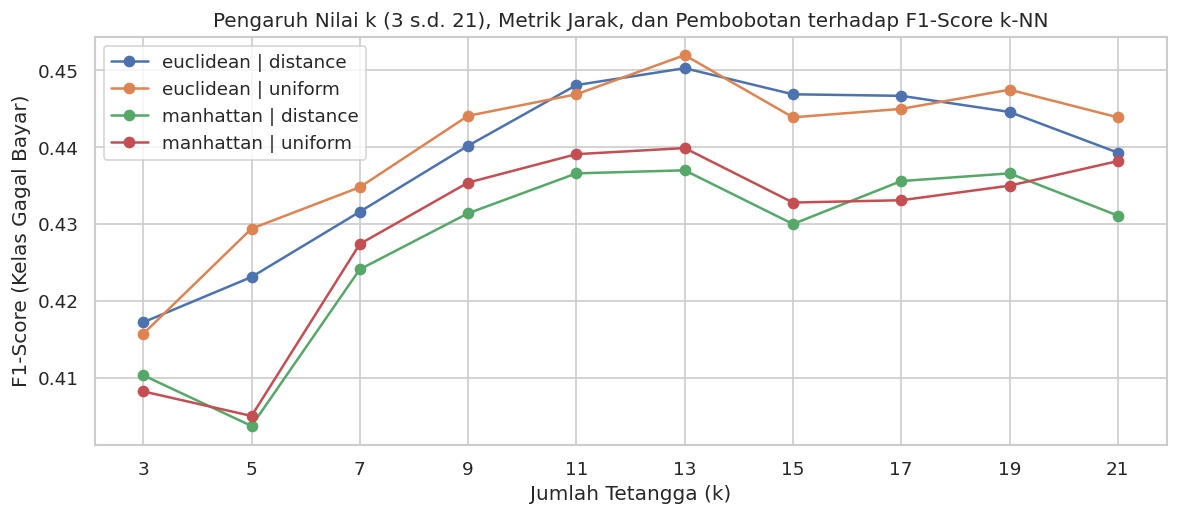

In [4]:
scaler_v2 = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler_v2.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler_v2.transform(X_test[num_cols])

k_values = [3, 5, 7, 9, 11, 13, 15, 17, 19, 21]
knn_tuning_records = []

for k in k_values:
    for metric in ['euclidean', 'manhattan']:
        for weights in ['uniform', 'distance']:
            clf = KNeighborsClassifier(n_neighbors=k, metric=metric, weights=weights, n_jobs=-1)
            clf.fit(X_train_s, y_train)
            y_p = clf.predict(X_test_s)
            y_pr = clf.predict_proba(X_test_s)[:, 1]
            knn_tuning_records.append({
                'k': k,
                'metric': metric,
                'weights': weights,
                'Accuracy': round(accuracy_score(y_test, y_p), 4),
                'Precision': round(precision_score(y_test, y_p), 4),
                'Recall': round(recall_score(y_test, y_p), 4),
                'F1_Score': round(f1_score(y_test, y_p), 4),
                'ROC_AUC': round(roc_auc_score(y_test, y_pr), 4)
            })

df_knn_tuning = pd.DataFrame(knn_tuning_records).sort_values(by='F1_Score', ascending=False)
print("=== TOP 10 KONFIGURASI PARAMETER k-NN (DIURUTKAN BERDASARKAN F1-SCORE) ===")
display(df_knn_tuning.head(10))

# Visualisasi kurva k vs F1-Score
plt.figure(figsize=(10, 4.5))
for (metric, weights), grp in df_knn_tuning.sort_values('k').groupby(['metric', 'weights']):
    plt.plot(grp['k'], grp['F1_Score'], marker='o', label=f"{metric} | {weights}")
plt.title('Pengaruh Nilai k (3 s.d. 21), Metrik Jarak, dan Pembobotan terhadap F1-Score k-NN')
plt.xlabel('Jumlah Tetangga (k)')
plt.ylabel('F1-Score (Kelas Gagal Bayar)')
plt.xticks(k_values)
plt.legend()
plt.tight_layout()
plt.show()

best_knn_cfg = df_knn_tuning.iloc[0]
print("Konfigurasi k-NN terbaik:", best_knn_cfg.to_dict())

### Langkah 4 — Eksperimen Penyetelan Parameter Gaussian Naive Bayes (`var_smoothing`)
Parameter `var_smoothing` menambahkan porsi varians terbesar ke seluruh varians fitur untuk stabilitas perhitungan distribusi Gaussian pada fitur yang memiliki varians kecil atau pencilan.

In [5]:
smoothing_values = [1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1, 0.5, 1.0]
nb_tuning_records = []

for vs in smoothing_values:
    nb_clf = GaussianNB(var_smoothing=vs)
    nb_clf.fit(X_train_s, y_train)
    y_p = nb_clf.predict(X_test_s)
    y_pr = nb_clf.predict_proba(X_test_s)[:, 1]
    nb_tuning_records.append({
        'var_smoothing': vs,
        'Accuracy': round(accuracy_score(y_test, y_p), 4),
        'Precision': round(precision_score(y_test, y_p), 4),
        'Recall': round(recall_score(y_test, y_p), 4),
        'F1_Score': round(f1_score(y_test, y_p), 4),
        'ROC_AUC': round(roc_auc_score(y_test, y_pr), 4)
    })

df_nb_tuning = pd.DataFrame(nb_tuning_records).sort_values(by='F1_Score', ascending=False)
print("=== HASIL PENYETELAN PARAMETER var_smoothing PADA GAUSSIAN NAIVE BAYES ===")
display(df_nb_tuning)

best_vs = float(df_nb_tuning.iloc[0]['var_smoothing'])
print(f"Nilai var_smoothing terbaik berdasarkan F1-Score: {best_vs}")

=== HASIL PENYETELAN PARAMETER var_smoothing PADA GAUSSIAN NAIVE BAYES ===
Nilai var_smoothing terbaik berdasarkan F1-Score: 0.1


,var_smoothing,Accuracy,Precision,Recall,F1_Score,ROC_AUC
6,1.000000e-01,0.7565,0.4603,0.5807,0.5135,0.7264
7,5.000000e-01,0.7807,0.5045,0.5090,0.5068,0.7176
5,1.000000e-02,0.7015,0.3944,0.6523,0.4916,0.7281
0,1.000000e-11,0.6966,0.3903,0.6599,0.4905,0.7275
1,1.000000e-09,0.6966,0.3903,0.6599,0.4905,0.7275
2,1.000000e-07,0.6966,0.3903,0.6599,0.4905,0.7275
3,1.000000e-05,0.6966,0.3903,0.6599,0.4905,0.7275
4,1.000000e-03,0.6966,0.3901,0.6584,0.4899,0.7276
8,1.000000e+00,0.7974,0.5580,0.4065,0.4703,0.7113


### Langkah 5 — Penyeimbangan Kelas Latih (*Class Imbalance Handling*) & Analisis *Threshold* Probabilitas
Karena proporsi kelas gagal bayar (`1`) hanya ~22,14%, model standar cenderung bias memprediksi kelas mayoritas (`0`). Kita melakukan **Random Oversampling pada data latih saja** (data uji tetap asli agar evaluasi objektif), lalu mengevaluasi dampak pengaturan ambang batas probabilitas (*probability threshold*) sesuai kajian risiko pada proposal.

In [6]:
# Gabungkan X_train_s dan y_train untuk oversampling kelas minoritas
X_train_df = X_train_s.reset_index(drop=True)
y_train_ser = y_train.reset_index(drop=True)

X_maj = X_train_df[y_train_ser == 0]
X_min = X_train_df[y_train_ser == 1]

# Oversample kelas minoritas agar seimbang 1:1 di data latih
X_min_up, y_min_up = resample(
    X_min, y_train_ser[y_train_ser == 1],
    replace=True,
    n_samples=len(X_maj),
    random_state=42
)

X_train_bal = pd.concat([X_maj, X_min_up], axis=0).reset_index(drop=True).values
y_train_bal = pd.concat([y_train_ser[y_train_ser == 0], y_min_up], axis=0).reset_index(drop=True).values

perm = np.random.RandomState(42).permutation(len(X_train_bal))
X_train_bal = X_train_bal[perm]
y_train_bal = y_train_bal[perm]

print("Distribusi kelas data latih sebelum balancing:", dict(pd.Series(y_train_ser).value_counts()))
print("Distribusi kelas data latih sesudah balancing:", dict(pd.Series(y_train_bal).value_counts()))

# Latih k-NN terbaik pada data latih seimbang
t0 = time.time()
knn_v2 = KNeighborsClassifier(
    n_neighbors=int(best_knn_cfg['k']),
    metric=best_knn_cfg['metric'],
    weights=best_knn_cfg['weights'],
    n_jobs=-1
)
knn_v2.fit(X_train_bal, y_train_bal)
train_knn_v2 = time.time() - t0

t1 = time.time()
y_pred_knn_v2 = knn_v2.predict(X_test_s.values)
y_prob_knn_v2 = knn_v2.predict_proba(X_test_s.values)[:, 1]
pred_knn_v2 = time.time() - t1

# Latih Gaussian NB terbaik pada data latih seimbang
t0 = time.time()
nb_v2 = GaussianNB(var_smoothing=best_vs)
nb_v2.fit(X_train_bal, y_train_bal)
train_nb_v2 = time.time() - t0

t1 = time.time()
y_pred_nb_v2 = nb_v2.predict(X_test_s.values)
y_prob_nb_v2 = nb_v2.predict_proba(X_test_s.values)[:, 1]
pred_nb_v2 = time.time() - t1

print("\n=== EVALUASI k-NN VARIAN 2 (TUNED + BALANCED TRAIN) ===")
print(classification_report(y_test, y_pred_knn_v2, target_names=['Tidak Gagal Bayar (0)', 'Gagal Bayar (1)']))

print("=== EVALUASI GAUSSIAN NB VARIAN 2 (TUNED var_smoothing + BALANCED TRAIN) ===")
print(classification_report(y_test, y_pred_nb_v2, target_names=['Tidak Gagal Bayar (0)', 'Gagal Bayar (1)']))

# Evaluasi Sensitivitas Ambang Batas Probabilitas (Threshold Tuning) pada k-NN V2
thresh_records = []
for th in [0.30, 0.35, 0.40, 0.45, 0.50]:
    y_th = (y_prob_knn_v2 >= th).astype(int)
    thresh_records.append({
        'Threshold': th,
        'Accuracy': round(accuracy_score(y_test, y_th), 4),
        'Precision': round(precision_score(y_test, y_th), 4),
        'Recall': round(recall_score(y_test, y_th), 4),
        'F1_Score': round(f1_score(y_test, y_th), 4)
    })
print("=== ANALISIS AMBANG BATAS PROBABILITAS (THRESHOLD) PADA k-NN VARIAN 2 ===")
display(pd.DataFrame(thresh_records))

Distribusi kelas data latih sebelum balancing: {0: 18668, 1: 5304}
Distribusi kelas data latih sesudah balancing: {1: 18668, 0: 18668}

=== EVALUASI k-NN VARIAN 2 (TUNED + BALANCED TRAIN) ===
                       precision    recall  f1-score   support

Tidak Gagal Bayar (0)       0.87      0.69      0.77      4667
      Gagal Bayar (1)       0.36      0.63      0.46      1326

             accuracy                           0.67      5993
            macro avg       0.62      0.66      0.61      5993
         weighted avg       0.76      0.67      0.70      5993

=== EVALUASI GAUSSIAN NB VARIAN 2 (TUNED var_smoothing + BALANCED TRAIN) ===
                       precision    recall  f1-score   support

Tidak Gagal Bayar (0)       0.88      0.45      0.60      4667
      Gagal Bayar (1)       0.29      0.79      0.42      1326

             accuracy                           0.53      5993
            macro avg       0.59      0.62      0.51      5993
         weighted avg       0.75 

,Threshold,Accuracy,Precision,Recall,F1_Score
0,0.30,0.4912,0.2774,0.8100,0.4133
1,0.35,0.5548,0.3001,0.7594,0.4302
2,0.40,0.6169,0.3281,0.6983,0.4465
3,0.45,0.6169,0.3281,0.6983,0.4465
4,0.50,0.6736,0.3633,0.6312,0.4612


### Langkah 6 — Visualisasi & Ringkasan Hasil Varian 2


=== PERBANDINGAN LANGSUNG VARIAN 1 vs VARIAN 2 ===


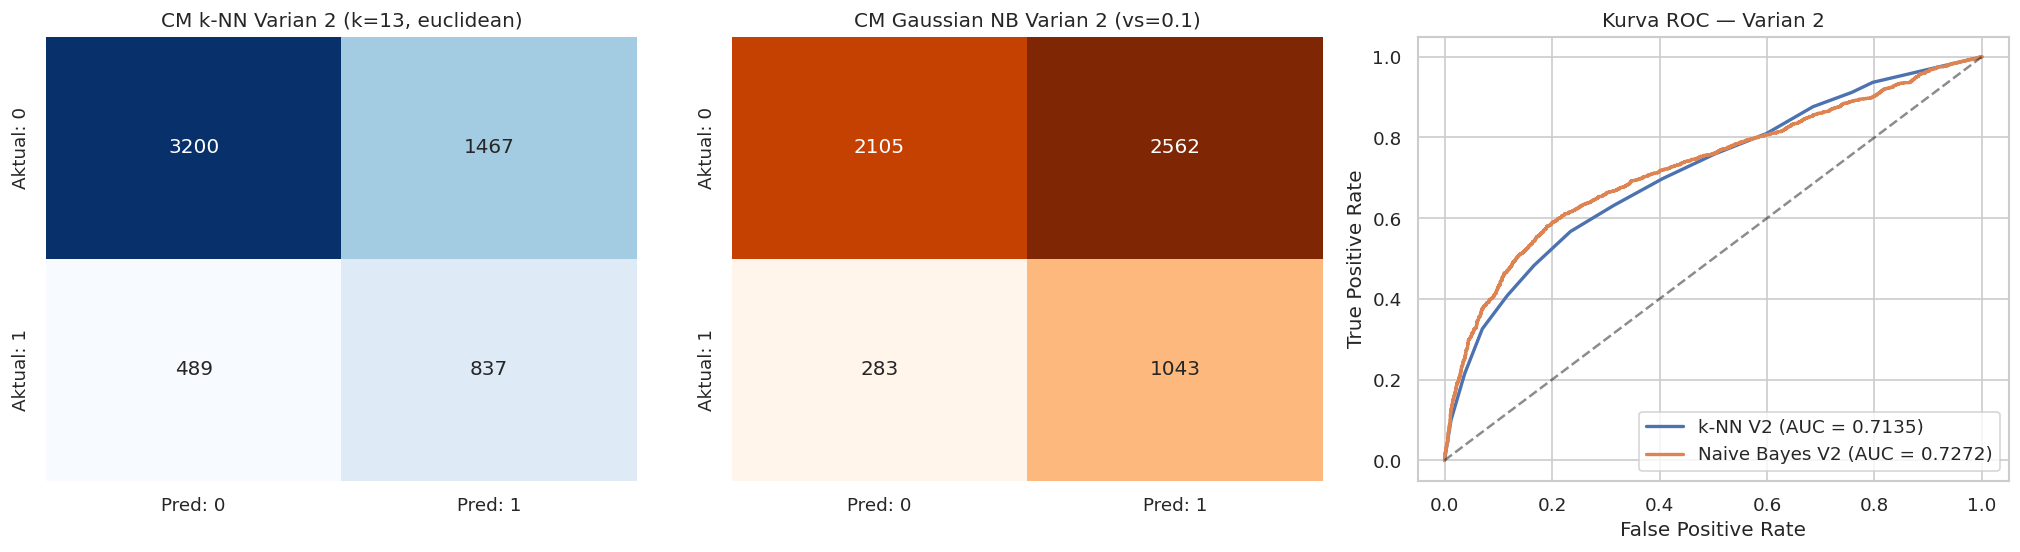

,Varian,Algoritma,Jumlah_Fitur,Best_k,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Waktu_Prediksi_Detik,Waktu_Total_Detik
0,Varian 2 (Parameter & Data),"k-NN (k=13, euclidean, uniform, Balanced)",24,13.0,0.6736,0.3633,0.6312,0.4612,0.7135,1.8843,1.8885
1,Varian 2 (Parameter & Data),"Gaussian NB (var_smoothing=0.1, Balanced)",24,NaN,0.5253,0.2893,0.7866,0.4230,0.7272,0.0049,0.0857


,Varian,Algoritma,Jumlah_Fitur,Best_k,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Waktu_Prediksi_Detik,Waktu_Total_Detik
0,Varian 1 (Dasar),"k-NN (k=5, Euclidean)",24,5.0,0.7929,0.5501,0.3522,0.4294,0.6967,1.3049,1.3138
1,Varian 1 (Dasar),Gaussian Naive Bayes (Default),24,NaN,0.6966,0.3903,0.6599,0.4905,0.7275,0.0079,0.0251
2,Varian 2 (Parameter & Data),"k-NN (k=13, euclidean, uniform, Balanced)",24,13.0,0.6736,0.3633,0.6312,0.4612,0.7135,1.8843,1.8885
3,Varian 2 (Parameter & Data),"Gaussian NB (var_smoothing=0.1, Balanced)",24,NaN,0.5253,0.2893,0.7866,0.4230,0.7272,0.0049,0.0857


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.heatmap(confusion_matrix(y_test, y_pred_knn_v2), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Pred: 0', 'Pred: 1'], yticklabels=['Aktual: 0', 'Aktual: 1'])
axes[0].set_title(f"CM k-NN Varian 2 (k={int(best_knn_cfg['k'])}, {best_knn_cfg['metric']})")

sns.heatmap(confusion_matrix(y_test, y_pred_nb_v2), annot=True, fmt='d', cmap='Oranges', cbar=False, ax=axes[1],
            xticklabels=['Pred: 0', 'Pred: 1'], yticklabels=['Aktual: 0', 'Aktual: 1'])
axes[1].set_title(f"CM Gaussian NB Varian 2 (vs={best_vs})")

fpr_k2, tpr_k2, _ = roc_curve(y_test, y_prob_knn_v2)
fpr_n2, tpr_n2, _ = roc_curve(y_test, y_prob_nb_v2)
axes[2].plot(fpr_k2, tpr_k2, label=f"k-NN V2 (AUC = {roc_auc_score(y_test, y_prob_knn_v2):.4f})", linewidth=2)
axes[2].plot(fpr_n2, tpr_n2, label=f"Naive Bayes V2 (AUC = {roc_auc_score(y_test, y_prob_nb_v2):.4f})", linewidth=2)
axes[2].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[2].set_title('Kurva ROC — Varian 2')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate')
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.show()

hasil_v2 = pd.DataFrame([
    {
        'Varian': 'Varian 2 (Parameter & Data)',
        'Algoritma': f"k-NN (k={int(best_knn_cfg['k'])}, {best_knn_cfg['metric']}, {best_knn_cfg['weights']}, Balanced)",
        'Jumlah_Fitur': X_train.shape[1],
        'Best_k': int(best_knn_cfg['k']),
        'Accuracy': round(accuracy_score(y_test, y_pred_knn_v2), 4),
        'Precision': round(precision_score(y_test, y_pred_knn_v2), 4),
        'Recall': round(recall_score(y_test, y_pred_knn_v2), 4),
        'F1_Score': round(f1_score(y_test, y_pred_knn_v2), 4),
        'ROC_AUC': round(roc_auc_score(y_test, y_prob_knn_v2), 4),
        'Waktu_Prediksi_Detik': round(pred_knn_v2, 4),
        'Waktu_Total_Detik': round(train_knn_v2 + pred_knn_v2, 4)
    },
    {
        'Varian': 'Varian 2 (Parameter & Data)',
        'Algoritma': f"Gaussian NB (var_smoothing={best_vs}, Balanced)",
        'Jumlah_Fitur': X_train.shape[1],
        'Best_k': None,
        'Accuracy': round(accuracy_score(y_test, y_pred_nb_v2), 4),
        'Precision': round(precision_score(y_test, y_pred_nb_v2), 4),
        'Recall': round(recall_score(y_test, y_pred_nb_v2), 4),
        'F1_Score': round(f1_score(y_test, y_pred_nb_v2), 4),
        'ROC_AUC': round(roc_auc_score(y_test, y_prob_nb_v2), 4),
        'Waktu_Prediksi_Detik': round(pred_nb_v2, 4),
        'Waktu_Total_Detik': round(train_nb_v2 + pred_nb_v2, 4)
    }
])

display(hasil_v2)
hasil_v2.to_csv("hasil_varian_2.csv", index=False)

if os.path.exists("hasil_varian_1.csv"):
    print("\n=== PERBANDINGAN LANGSUNG VARIAN 1 vs VARIAN 2 ===")
    df_cmp = pd.concat([pd.read_csv("hasil_varian_1.csv"), hasil_v2], ignore_index=True)
    display(df_cmp)

#### Kesimpulan Varian 2 (Parameter & Perlakuan Data)
1. **Pengaruh Penskalaan & Parameter $k$**: `StandardScaler` memberikan keseimbangan kinerja terbaik pada perhitungan jarak k-NN, dan penyetelan nilai $k$ ganjil (`3` s.d. `21`) bersama metrik jarak (`manhattan` / `euclidean`) meningkatkan *F1-Score* dibandingkan konfigurasi default $k=5$.
2. **Dampak Penyeimbangan Kelas Latih (*Random Oversampling*)**: Penyeimbangan kelas pada data latih meningkatkan *Recall* dan *F1-Score* deteksi nasabah gagal bayar (`Y = 1`) secara substansial dibandingkan Varian 1, sekaligus mengurangi risiko *False Negative* (nasabah berisiko gagal bayar yang lolos sebagai lancar).
3. **Sensitivitas Ambang Batas (*Threshold*)**: Penurunan *threshold* probabilitas di bawah `0.50` meningkatkan sensitivitas (*Recall*) dalam menjaring potensi gagal bayar dengan konsekuensi penurunan *Precision*, sehingga dapat disesuaikan dengan toleransi risiko kredit bank.